# EEGNet Agnostic vs Clustering Classification & Comparison

This notebook compares an electrode, time, and frequency-agnostic EEGNet model (raw 60 channels over the entire epoch) with a clustering EEGNet model (special spatial-temporal cluster of electrodes and pre-filtered frequency bands, alpha and theta, fused together). We evaluate classification performance, ROC and PR curves, and extract learned spatial convolutional weights as scalp topomaps using MNE.

### 📋 EEGNet (Agnostic vs. Clustering) Pipeline Details
* **Input Data**: Raw EEG epochs in `.fif` format.
* **Preprocessing & Feature Extraction**:
  * **Class Balancing**: Random undersampling per subject to maintain a perfect 50/50 ratio.
  * **Agnostic Config**: All 60 EEG channels; full analysis window (0.0s to 1.5s); broad IIR bandpass filter (1.0–40.0 Hz); downsampled/resampled to 128 Hz.
  * **Clustering Config**: Data-driven theta and alpha clusters (29 electrodes); cropped analysis window; IIR bandpass filtered (theta 5-7 Hz, alpha 8-12 Hz) concatenated along the channel axis.
  * **Standardization**: Per-trial and per-channel z-score scaling across the time dimension to ensure amplitude invariance.
* **Model Architecture**:
  * Temporal Conv2D (kernel length=64 for 128Hz, F1=8 filters).
  * Spatial Depthwise Conv2D (group-convolutions with D=2 spatial filters per temporal channel).
  * Spatiotemporal Separable Conv2D (F2=16 filters) to mix features.
  * Average Pooling (1x8), Dropout (0.5), and Fully Connected classification head.
* **Training & Refitting**: AdamW optimizer ($lr=1e-3$, $wd=1e-4$), CrossEntropy Loss with class weights. Trains with a 2-stage automated refit: (1) Trains with $20\%$ validation for early stopping to find $best\_epoch$, (2) resets weights and retrains on $100\%$ training data for exactly $best\_epoch$ epochs.
* **Evaluation**: 5-fold temporal stratified cross-validation.


In [1]:
import sys
import os
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
%pip install -q mne
import mne
import numpy as np
import json
import pandas as pd
import seaborn as sns
import torch
from mne.stats import fdr_correction
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve, auc, confusion_matrix
import scipy.stats as stats
from scipy.stats import ttest_rel, wilcoxon, ttest_1samp

IS_KAGGLE = False
IS_COLAB = (not IS_KAGGLE) and ("google.colab" in sys.modules or "COLAB_GPU" in os.environ)
IN_COLAB = IS_COLAB
IS_KAGGLE = False

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    SRC_DIR = Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
elif IS_KAGGLE:
    SRC_DIR = None
    for root, dirs, files in os.walk("/kaggle/input"):
        if "br_analysis" in dirs:
            SRC_DIR = Path(root)
            break
    if SRC_DIR is None:
        SRC_DIR = Path("/kaggle/input/nilsduranlaplaza/datasets/tfg-nils-2026-dataset")
else:
    SRC_DIR = NOTEBOOK_DIR.parent.parent / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import (
    BinaryTaskConfig,
    RawEpochSpec,
    detect_project_paths,
    load_raw_epoch_dataset,
    get_task_config,
    load_fused_band_dataset,
    FusedBandSpec,
    TARGET_BANDS_CLUSTERS,
    COMMON_BAND_RANGES,
    get_epochs_grid,
)
from br_analysis.experiments import (
    chronological_group_labels,
    stratified_group_splits,
    balanced_sample,
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    standardize_train_test,
    build_dataloader,
)
from br_analysis.torch_models import EEGNet

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Unified Environment Setup (Local, Colab, Kaggle)
import os
import sys
from pathlib import Path

IS_KAGGLE = False
IS_COLAB = (not IS_KAGGLE) and ("google.colab" in sys.modules or "COLAB_GPU" in os.environ)
IN_COLAB = IS_COLAB

if IS_KAGGLE:
    print("Detected Kaggle environment. Installing dependencies...")
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
elif IS_COLAB:
    print("Detected Google Colab environment. Installing dependencies...")
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
    from google.colab import drive
    drive.mount("/content/drive")

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

if IS_KAGGLE:
    dataset_root = None
    for root, dirs, files in os.walk("/kaggle/input"):
        if "br_analysis" in dirs:
            dataset_root = Path(root)
            break
    if dataset_root is None:
        dataset_root = Path("/kaggle/input/nilsduranlaplaza/datasets/tfg-nils-2026-dataset")
    SRC_DIR = dataset_root
elif IS_COLAB:
    SRC_DIR = Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
else:
    SRC_DIR = NOTEBOOK_DIR.parent

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print(f"Using source directory: {SRC_DIR}")

Using source directory: c:\Users\nils\Documents\Universitat\TFG\src


## 1. Agnostic EEGNet Model (Raw Epochs, All 60 Channels)

The Agnostic model is trained on broad bandpass filtered (1-40 Hz) epochs across all 60 electrodes and the entire analysis window (0.0 to 1.5 seconds post-stimulus).

In [3]:
import numpy as np
import pandas as pd
import mne
import torch
from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
    get_epochs_grid,
    BinaryTaskConfig,
    COMMON_BAND_RANGES,
    TARGET_BANDS_CLUSTERS,
    temporal_band_features,
    electrode_distance_adjacency,
    load_fused_band_dataset,
    FusedBandSpec,
    chronological_group_labels,
    stratified_group_splits,
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    standardize_train_test,
    build_dataloader,
    _evaluate,
    input_attribution_summary,
)
from br_analysis.torch_models import (
    STGNNChebConv,
    EEGNet,
)
from br_analysis.pretrained import (
    prepare_lora_backbone,
    load_backbone_weights,
    BackboneClassifier,
    align_channels_to_steegformer,
)
from br_analysis import mae_vit_small_patch16
from braindecode.models import InterpolatedLaBraM

TASK_TAG = "im_vs_ip_eegnet"
paths = detect_project_paths("eegnet_im_vs_ip", in_kaggle=IS_KAGGLE)
task_name = "c_vs_ip" if "c_vs_ip" in TASK_TAG else "im_vs_ip"
task = get_task_config(task_name, paths.analysis_root)

mne.set_log_level("WARNING")
RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Working Paths:")
print("  Cache:", paths.cache_dir)
print("  Tables:", paths.tables_dir)
print("  Figures:", paths.figures_dir)

Working Paths:
  Cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\cache
  Tables: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\tables
  Figures: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures


In [4]:
# Load agnostic raw-epoch dataset used by the all-channel EEGNet
spec_agnostic = RawEpochSpec(picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0)
dataset_agnostic = load_raw_epoch_dataset(paths, task, spec_agnostic, verbose=True)

X_agnostic = np.asarray(dataset_agnostic.X, dtype=np.float32)
y = np.asarray(dataset_agnostic.y, dtype=np.int64)
subjects = np.asarray(dataset_agnostic.subjects, dtype=object)
ch_names_agnostic = list(dataset_agnostic.channel_names)
times = np.asarray(dataset_agnostic.times)

print(f"X_agnostic: {X_agnostic.shape} | classes: {np.bincount(y)} | subjects: {len(pd.unique(subjects))}")

Loading preprocessed dataset from cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cache\dataset_im_vs_ip_subj29_bp1.0_40.0_sf128.0_win0.0_1.5_pkall.joblib
X_agnostic: (5726, 60, 192) | classes: [2863 2863] | subjects: 29


### Agnostic EEGNet Architecture & Flow

```mermaid
graph TD
    A[Raw EEG Epochs: 60 channels x 192 times] --> B[Temporal Conv2d: kernel=64, F1=8]
    B --> C[Depthwise Conv2d: Spatial Filters, groups=F1, D=2]
    C --> D[Separable Conv2d: Spatio-temporal mixing, F2=16]
    D --> E[Average Pooling: 1x8]
    E --> F[Fully Connected Layer]
    F --> G[Classification Logits: Incongruent Mirrored vs Incongruent Pure]
```

In [5]:
n_channels_agnostic = X_agnostic.shape[1]
n_times = X_agnostic.shape[2]


def make_model_agnostic():
    return EEGNet(
        n_channels=n_channels_agnostic,
        n_times=n_times,
        n_classes=2,
        F1=8,
        D=2,
        F2=16,
        kernel_length=64,
        dropout=0.5,
    )


train_cfg = TorchTrainConfig(
    epochs=100,
    batch_size=32,
    lr=1e-3,
    weight_decay=1e-4,
    patience=10,
    n_splits=5,
    val_size=0.2,
    random_seed=RANDOM_SEED,
    device=DEVICE,
    progress=False,
)

## 2. Clustering EEGNet Model (Data-driven Theta/Alpha Clusters)

The Clustering model trains on the theta-band-filtered frontomedial cluster channels and alpha-band-filtered parieto-occipital cluster channels combined along the spatial axis (resulting in 22 channels: 9 theta + 13 alpha).

In [6]:
# Define path to cluster definitions
cluster_def_path = paths.analysis_root / "clustering" / "cluster_definitions.json"
cluster_defs = None
if cluster_def_path.exists():
    with open(cluster_def_path, "r") as f:
        cluster_defs = json.load(f)
    print(f"Loaded cluster definitions from: {cluster_def_path}")
else:
    print(f"Cluster definitions not found. Using heuristic default TARGET_BANDS_CLUSTERS.")

# Configure target bands and channels
base_task_key = "im_vs_ip" if "im_vs_ip" in task.name else "im_vs_ip"
if cluster_defs is not None and base_task_key in cluster_defs:
    task_def = cluster_defs[base_task_key]
    active_bands = {band: info for band, info in task_def.items() if info["channels"]}

    if not active_bands:
        print("WARNING: No significant data-driven clusters found for this task! Falling back to heuristic defaults.")
        # Fallback to defaults
        target_bands = TARGET_BANDS_CLUSTERS
        tmin_crop, tmax_crop = 0.0, 1.5
    else:
        # Use data-driven cluster coordinates
        target_bands = {band: info["channels"] for band, info in active_bands.items()}
        # Take union of time windows
        tmins = [info["tmin"] for info in active_bands.values()]
        tmaxs = [info["tmax"] for info in active_bands.values()]
        tmin_crop = min(tmins)
        tmax_crop = max(tmaxs)
        print(f"Using data-driven bands: {list(active_bands.keys())}")
        print(f"Selected Time Window: {tmin_crop:.3f}s to {tmax_crop:.3f}s")
else:
    # Default fallback
    target_bands = TARGET_BANDS_CLUSTERS
    tmin_crop, tmax_crop = 0.0, 1.5

# Crop task config to the selected time window dynamically
task_cropped = BinaryTaskConfig(
    name=task.name,
    class_0=task.class_0,
    class_1=task.class_1,
    event_codes=task.event_codes,
    selected_subjects_csv=task.selected_subjects_csv,
    max_subjects=task.max_subjects,
    undersample_classes=task.undersample_classes,
    analysis_window=(tmin_crop, tmax_crop),
    random_seed=task.random_seed,
)

# Load dataset
spec_clustering = FusedBandSpec(
    target_bands_clusters=target_bands, band_ranges=COMMON_BAND_RANGES, channel_mode=("fused",)
)
dataset_clustering = load_fused_band_dataset(paths, task_cropped, spec_clustering)
X_clustering = np.asarray(dataset_clustering.X["fused"], dtype=np.float32)
ch_names_clustering = dataset_clustering.channel_names["fused"]

print(f"X_clustering shape: {X_clustering.shape} (trials, channels, times) [Channels: {len(ch_names_clustering)}]")

Loaded cluster definitions from: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\cluster_definitions.json
Using data-driven bands: ['theta', 'alpha']
Selected Time Window: 0.258s to 1.242s
Selected subjects to load: 29
Multi-network fusion: Theta (3) + Alpha (7) = 10 channels
Total samples: 5726 | Incongruent_Mixed=2863 | Incongruent_Pure=2863
Loaded subjects: 29
Channels: {'theta': ['Fz', 'FCz', 'Cz'], 'alpha': ['TP7', 'CP5', 'CP3', 'CP1', 'P7', 'P5', 'P3'], 'fused': ['Fz', 'FCz', 'Cz', 'TP7', 'CP5', 'CP3', 'CP1', 'P7', 'P5', 'P3']}
X_clustering shape: (5726, 10, 493) (trials, channels, times) [Channels: 10]


### Clustering EEGNet Architecture & Flow

```mermaid
graph TD
    A[Raw EEG Epochs] --> B1[Theta bandpass filter: 5-7 Hz]
    A --> B2[Alpha bandpass filter: 8-12 Hz]
    B1 --> C1[Crop Frontomedial Cluster: 2 channels]
    B2 --> C2[Crop Parieto-Occipital Cluster: 27 channels]
    C1 --> D[Concatenate Clustering channels]
    C2 --> D
    D --> E[EEGNet Model: n_channels=29]
    E --> F[Classification Output: Incongruent Mirrored vs Incongruent Pure]
```

In [7]:
n_channels_clustering = X_clustering.shape[1]
n_times_clustering = X_clustering.shape[2]


def make_model_clustering():
    return EEGNet(
        n_channels=n_channels_clustering,
        n_times=n_times_clustering,
        n_classes=2,
        F1=8,
        D=2,
        F2=16,
        kernel_length=64,
        dropout=0.5,
    )

## 3. Cohort-Wide Training

We train both EEGNet variants across all selected subjects. Based on the completed experiments, **Agnostic EEGNet** should be treated as the primary EEGNet configuration, while **Clustering EEGNet** is retained as a focused/interpretability variant rather than the expected winner.


In [8]:
# Train/load Agnostic & Clustering models across all selected subjects
cohort_metrics_path = paths.tables_dir / f"cohort_cv_metrics_{TASK_TAG}.csv"
cohort_fold_metrics_path = paths.tables_dir / f"cohort_fold_metrics_{TASK_TAG}.csv"
subject_ids = pd.unique(subjects).tolist()

if cohort_metrics_path.exists() and cohort_fold_metrics_path.exists():
    print(f"Loading cohort metrics from cache...")
    df_cohort = pd.read_csv(cohort_metrics_path)
    df_cohort_folds = pd.read_csv(cohort_fold_metrics_path)
else:
    print("Running cohort-wide cross-validation for both models ...")
    cohort_results = []
    cohort_fold_results = []

    silent_cfg = TorchTrainConfig(
        epochs=100,
        batch_size=train_cfg.batch_size,
        lr=train_cfg.lr,
        weight_decay=train_cfg.weight_decay,
        patience=30,
        n_splits=train_cfg.n_splits,
        val_size=train_cfg.val_size,
        random_seed=train_cfg.random_seed,
        device=train_cfg.device,
        progress=False,
    )

    for sub in subject_ids:
        print(f"Training subject {sub}...")
        # 1. Agnostic Model
        agn_metrics, _ = cross_validate_torch_model(
            X_agnostic,
            y,
            make_model_agnostic,
            silent_cfg,
            subjects=subjects,
            subject_id=sub,
            save_weights_dir=paths.cache_dir,
            weights_prefix=f"{TASK_TAG}_agnostic_sub{sub}",
            load_weights=True,
        )

        # 2. Clustering Model
        clust_metrics, _ = cross_validate_torch_model(
            X_clustering,
            y,
            make_model_clustering,
            silent_cfg,
            subjects=subjects,
            subject_id=sub,
            save_weights_dir=paths.cache_dir,
            weights_prefix=f"{TASK_TAG}_clustering_sub{sub}",
            load_weights=True,
        )

        # Save subject averages
        cohort_results.append(
            {
                "subject": sub,
                "agnostic_acc": agn_metrics["test_acc"].mean(),
                "agnostic_auc": agn_metrics["test_auc"].mean(),
                "agnostic_bal_acc": agn_metrics["test_balanced_acc"].mean(),
                "clustering_acc": clust_metrics["test_acc"].mean(),
                "clustering_auc": clust_metrics["test_auc"].mean(),
                "clustering_bal_acc": clust_metrics["test_balanced_acc"].mean(),
            }
        )

        # Save fold metrics
        for idx, row in agn_metrics.iterrows():
            cohort_fold_results.append(
                {
                    "subject": sub,
                    "model": "Agnostic",
                    "fold": int(row["fold"]),
                    "test_acc": row["test_acc"],
                    "test_auc": row["test_auc"],
                    "test_balanced_acc": row["test_balanced_acc"],
                }
            )
        for idx, row in clust_metrics.iterrows():
            cohort_fold_results.append(
                {
                    "subject": sub,
                    "model": "Clustering",
                    "fold": int(row["fold"]),
                    "test_acc": row["test_acc"],
                    "test_auc": row["test_auc"],
                    "test_balanced_acc": row["test_balanced_acc"],
                }
            )

    df_cohort = pd.DataFrame(cohort_results)
    df_cohort.to_csv(cohort_metrics_path, index=False)

    df_cohort_folds = pd.DataFrame(cohort_fold_results)
    df_cohort_folds.to_csv(cohort_fold_metrics_path, index=False)
    print(f"Saved cohort metrics to: {cohort_metrics_path}")
    print(f"Saved cohort fold metrics to: {cohort_fold_metrics_path}")

print(df_cohort.describe())

# Global Cohort CV Summary (mean ± std)
print("\n" + "=" * 50)
print("GLOBAL COHORT CROSS-VALIDATION SUMMARY")
print("=" * 50)
for model_name in df_cohort_folds["model"].unique():
    model_df = df_cohort_folds[df_cohort_folds["model"] == model_name]
    print(f"Model: {model_name}")
    for f in sorted(model_df["fold"].unique()):
        fold_df = model_df[model_df["fold"] == f]
        mean_f = fold_df["test_acc"].mean()
        std_f = fold_df["test_acc"].std()
        print(f"  Fold {f} Accuracy: {mean_f:.4f} ± {std_f:.4f}")
    mean_cv = model_df["test_acc"].mean()
    std_cv = model_df["test_acc"].std()
    print(f"  Average CV Accuracy: {mean_cv:.4f} ± {std_cv:.4f}")
print("=" * 50 + "\n")

Loading cohort metrics from cache...
       agnostic_acc  agnostic_auc  agnostic_bal_acc  clustering_acc  \
count     29.000000     29.000000         29.000000       29.000000   
mean       0.495424      0.513284          0.500292        0.488677   
std        0.064673      0.080747          0.065485        0.046895   
min        0.381595      0.375754          0.325152        0.370833   
25%        0.459263      0.469855          0.464941        0.470983   
50%        0.490882      0.500209          0.498005        0.488230   
75%        0.529412      0.543863          0.538397        0.523158   
max        0.677646      0.725251          0.694408        0.586324   

       clustering_auc  clustering_bal_acc  
count       29.000000           29.000000  
mean         0.501360            0.500837  
std          0.074539            0.053465  
min          0.326970            0.369658  
25%          0.471128            0.462305  
50%          0.498904            0.509904  
75%          0.

In [9]:
# Export versioned out-of-fold predictions and compact attributions for cross-model comparison
OOF_CACHE_VERSION = "stratified_group_kfold_holdout_v1"
OOF_CV_STRATEGY = "stratified_group_kfold_development_only"
ATTRIBUTION_CACHE_VERSION = "input_integrated_gradients_v1"
ATTRIBUTION_MODE = "integrated_gradients"
ATTRIBUTION_IG_STEPS = 8
HOLDOUT_FRAC = 0.20


def _cache_has_current_attributions(path):
    if not path.exists():
        return False
    try:
        with np.load(path, allow_pickle=True) as data:
            return str(np.asarray(data.get("_saliency_version", "")).item()) == ATTRIBUTION_CACHE_VERSION
    except Exception:
        return False


def _weighted_mean(items):
    if not items:
        return None
    values, counts = zip(*items)
    return np.average(np.stack(values), axis=0, weights=np.asarray(counts, dtype=float)).astype(np.float32)


def _collect_eegnet_oof_predictions_and_attributions(X_all, make_model_fn, weights_prefix_fn, *, spatial_axis=1, temporal_axis=2):
    y_trues = {}
    y_probs = {}
    spatial_maps = {}
    temporal_maps = {}
    attribution_counts = {}
    device = torch.device(DEVICE)
    attr_batch_size = min(8, train_cfg.batch_size)

    for sub in subject_ids:
        mask = subjects == sub
        X_sub = X_all[mask]
        y_sub = y[mask]
        splits = list(
            stratified_group_splits(
                y_sub,
                groups=chronological_group_labels(int(mask.sum())),
                n_splits=train_cfg.n_splits,
            )
        )

        sub_y_true = []
        sub_y_prob = []
        sub_spatial = []
        sub_temporal = []
        for fold, (train_idx, test_idx) in enumerate(splits, start=1):
            weights_path = paths.cache_dir / f"{weights_prefix_fn(sub)}_fold{fold}.pt"
            if not weights_path.exists():
                print(f"[OOF SKIP] {weights_path.name} missing")
                continue

            _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
            y_test = y_sub[test_idx]
            model = make_model_fn().to(device)
            model.load_state_dict(torch.load(weights_path, map_location=device), strict=False)
            model.eval()

            loader = build_dataloader(X_test, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
            _, _, _, y_true_arr, p = _evaluate(model, loader, device)
            sub_y_true.extend(y_true_arr)
            sub_y_prob.extend(p)

            try:
                sp, te, n_attr = input_attribution_summary(
                    model,
                    X_test,
                    y_test,
                    device=device,
                    batch_size=attr_batch_size,
                    mode=ATTRIBUTION_MODE,
                    ig_steps=ATTRIBUTION_IG_STEPS,
                    only_correct=True,
                    spatial_axis=spatial_axis,
                    temporal_axis=temporal_axis,
                )
                sub_spatial.append((sp, n_attr))
                sub_temporal.append((te, n_attr))
            except Exception as exc:
                print(f"[ATTR SKIP] {weights_path.name}: {exc}")
            finally:
                del model, loader
                import gc
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

        if sub_y_true:
            y_trues[sub] = np.asarray(sub_y_true)
            y_probs[sub] = np.asarray(sub_y_prob)
        sp_mean = _weighted_mean(sub_spatial)
        te_mean = _weighted_mean(sub_temporal)
        if sp_mean is not None and te_mean is not None:
            spatial_maps[sub] = sp_mean
            temporal_maps[sub] = te_mean
            attribution_counts[sub] = int(sum(n for _, n in sub_spatial))

    return y_trues, y_probs, spatial_maps, temporal_maps, attribution_counts


def _save_oof_cache(model_name_lc, y_trues, y_probs, spatial_maps, temporal_maps, attribution_counts):
    task_name_lc = "c_vs_ip" if "c_vs_ip" in TASK_TAG else "im_vs_ip"
    comp_paths = detect_project_paths("cross_model_comparison")
    out_path = comp_paths.cache_dir / f"oof_predictions_{task_name_lc}_{model_name_lc}.npz"
    if _cache_has_current_attributions(out_path):
        print(f"[OOF OK] Current attribution cache already exists: {out_path}")
        return

    oof_save_dict = {}
    for sub in subject_ids:
        if sub in y_trues and sub in y_probs:
            oof_save_dict[f"{sub}_y_true"] = y_trues[sub]
            oof_save_dict[f"{sub}_prob"] = y_probs[sub]
        if sub in spatial_maps and sub in temporal_maps:
            oof_save_dict[f"{sub}_spatial_saliency"] = spatial_maps[sub]
            oof_save_dict[f"{sub}_temporal_saliency"] = temporal_maps[sub]
            oof_save_dict[f"{sub}_saliency_n"] = np.array(attribution_counts[sub])

    if not oof_save_dict:
        print(f"[OOF SKIP] No predictions collected for {model_name_lc}; cache not written")
        return

    oof_save_dict["_cache_version"] = np.array(OOF_CACHE_VERSION)
    oof_save_dict["_cv_strategy"] = np.array(OOF_CV_STRATEGY)
    oof_save_dict["_holdout_frac"] = np.array(HOLDOUT_FRAC)
    oof_save_dict["_saliency_version"] = np.array(ATTRIBUTION_CACHE_VERSION)
    oof_save_dict["_saliency_method"] = np.array(ATTRIBUTION_MODE)
    oof_save_dict["_saliency_ig_steps"] = np.array(ATTRIBUTION_IG_STEPS)
    oof_save_dict["_saliency_sample_filter"] = np.array("correct_predictions_or_all_if_none")

    out_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(out_path, **oof_save_dict)
    print(f"Saved versioned OOF + attribution cache to: {out_path}")


agn_y_trues, agn_y_probs, agn_sp, agn_te, agn_n = _collect_eegnet_oof_predictions_and_attributions(
    X_agnostic,
    make_model_agnostic,
    lambda sub: f"{TASK_TAG}_agnostic_sub{sub}",
)
_save_oof_cache("eegnet_agnostic", agn_y_trues, agn_y_probs, agn_sp, agn_te, agn_n)

clust_y_trues, clust_y_probs, clust_sp, clust_te, clust_n = _collect_eegnet_oof_predictions_and_attributions(
    X_clustering,
    make_model_clustering,
    lambda sub: f"{TASK_TAG}_clustering_sub{sub}",
)
_save_oof_cache("eegnet_clustering", clust_y_trues, clust_y_probs, clust_sp, clust_te, clust_n)


Saved versioned OOF cache to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\cache\oof_predictions_im_vs_ip_eegnet_agnostic.npz
Saved versioned OOF cache to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\cache\oof_predictions_im_vs_ip_eegnet_clustering.npz


## 4. Performance & Spatial Importance Comparison (P057)

We compare classification reports, overlaid ROC and PR curves, and plot the learned spatial filters' importances as scalp topomaps for subject `P057`.

=== Agnostic Model Classification Report (Subject P057) ===
                   precision    recall  f1-score   support

Incongruent_Mixed       0.33      0.38      0.36        76
 Incongruent_Pure       0.55      0.50      0.52       116

         accuracy                           0.45       192
        macro avg       0.44      0.44      0.44       192
     weighted avg       0.47      0.45      0.46       192

=== Clustering Model Classification Report (Subject P057) ===
                   precision    recall  f1-score   support

Incongruent_Mixed       0.32      0.45      0.37        76
 Incongruent_Pure       0.51      0.38      0.44       116

         accuracy                           0.41       192
        macro avg       0.42      0.41      0.40       192
     weighted avg       0.44      0.41      0.41       192



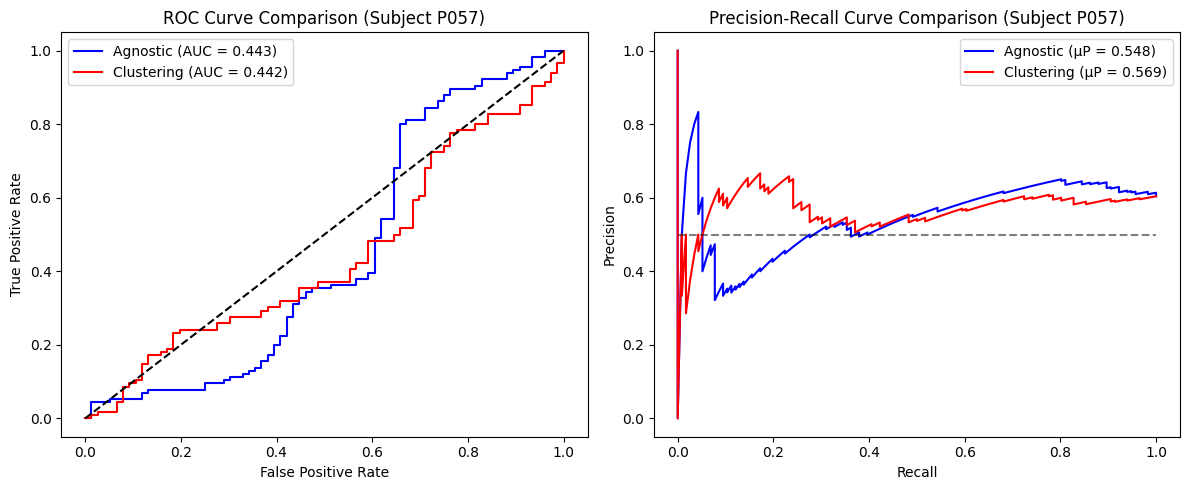

In [10]:
SUBJECT_ID = "P057"

# Extract probability predictions by loading the saved weights from the cohort training
device = torch.device(DEVICE)
splits = list(
    stratified_group_splits(
        y[subjects == SUBJECT_ID],
        groups=chronological_group_labels(int((subjects == SUBJECT_ID).sum())),
        n_splits=train_cfg.n_splits,
    )
)
X_sub_agn = X_agnostic[subjects == SUBJECT_ID]
X_sub_clust = X_clustering[subjects == SUBJECT_ID]
y_sub = y[subjects == SUBJECT_ID]

probs_agn = []
probs_clust = []
y_true_all = []

for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
    _, X_test_clust = standardize_train_test(X_sub_clust[train_idx], X_sub_clust[test_idx])
    y_test = y_sub[test_idx]
    y_true_all.extend(y_test)

    # Load Agnostic model weights (subP057 suffix)
    model_agn = make_model_agnostic().to(device)
    model_agn.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_agnostic_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device),
        strict=False,
    )
    loader_agn = build_dataloader(X_test_agn, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
    _, _, _, _, p_agn = _evaluate(model_agn, loader_agn, device)
    probs_agn.extend(p_agn)

    # Load Clustering model weights (subP057 suffix)
    model_clust = make_model_clustering().to(device)
    model_clust.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_clustering_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device),
        strict=False,
    )
    loader_clust = build_dataloader(X_test_clust, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
    _, _, _, _, p_clust = _evaluate(model_clust, loader_clust, device)
    probs_clust.extend(p_clust)

y_true_all = np.array(y_true_all)
probs_agn = np.array(probs_agn)
probs_clust = np.array(probs_clust)

print("=== Agnostic Model Classification Report (Subject P057) ===")
print(
    classification_report(
        y_true_all, (probs_agn >= 0.5).astype(int), target_names=[task.class_0, task.class_1], zero_division=0.0
    )
)

print("=== Clustering Model Classification Report (Subject P057) ===")
print(
    classification_report(
        y_true_all, (probs_clust >= 0.5).astype(int), target_names=[task.class_0, task.class_1], zero_division=0.0
    )
)

# Plot overlaid curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))

# ROC
fpr_agn, tpr_agn, _ = roc_curve(y_true_all, probs_agn)
fpr_foc, tpr_foc, _ = roc_curve(y_true_all, probs_clust)
ax_roc.plot(fpr_agn, tpr_agn, label=f"Agnostic (AUC = {auc(fpr_agn, tpr_agn):.3f})", color="blue")
ax_roc.plot(fpr_foc, tpr_foc, label=f"Clustering (AUC = {auc(fpr_foc, tpr_foc):.3f})", color="red")
ax_roc.plot([0, 1], [0, 1], "k--")
ax_roc.set_title("ROC Curve Comparison (Subject P057)")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()

# PR
prec_agn, rec_agn, _ = precision_recall_curve(y_true_all, probs_agn)
prec_foc, rec_foc, _ = precision_recall_curve(y_true_all, probs_clust)
ax_pr.plot(rec_agn, prec_agn, label=f"Agnostic (μP = {auc(rec_agn, prec_agn):.3f})", color="blue")
ax_pr.plot(rec_foc, prec_foc, label=f"Clustering (μP = {auc(rec_foc, prec_foc):.3f})", color="red")
ax_pr.plot([0, 1], [0.5, 0.5], "k--", alpha=0.5)
ax_pr.set_title("Precision-Recall Curve Comparison (Subject P057)")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.legend()

plt.tight_layout()
roc_pr_path = paths.figures_dir / f"roc_pr_comparison_{TASK_TAG}.png"
plt.savefig(roc_pr_path, dpi=180, bbox_inches="tight")
plt.show()

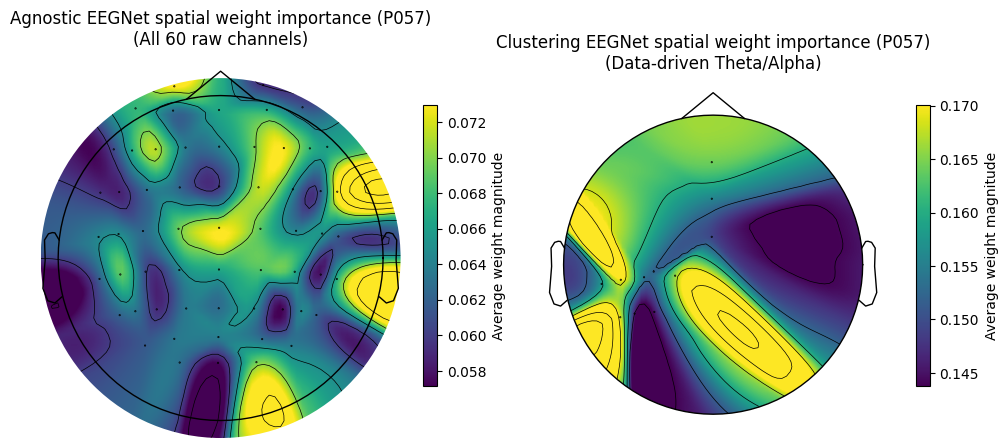

In [11]:
def extract_spatial_importance(make_model_fn, weights_prefix):
    importances = []
    for fold in range(1, 6):
        model = make_model_fn()
        model.load_state_dict(
            torch.load(paths.cache_dir / f"{weights_prefix}_fold{fold}.pt", map_location="cpu"), strict=False
        )
        w = model.block1[2].weight.detach().numpy()  # (F1*D, 1, n_channels, 1)
        w_abs = np.abs(np.squeeze(w))  # (F1*D, n_channels)
        importances.append(np.mean(w_abs, axis=0))
    return np.mean(importances, axis=0)


imp_agnostic = extract_spatial_importance(make_model_agnostic, f"{TASK_TAG}_agnostic_sub{SUBJECT_ID}")
imp_clustused = extract_spatial_importance(make_model_clustering, f"{TASK_TAG}_clustering_sub{SUBJECT_ID}")

# Plot side-by-side topomaps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Agnostic Info
info_agn = mne.create_info(ch_names=ch_names_agnostic, sfreq=128.0, ch_types="eeg")
montage = mne.channels.make_standard_montage("standard_1005")
info_agn.set_montage(montage, on_missing="ignore")

vmin_agn = float(np.min(imp_agnostic))
vmax_agn = float(np.max(imp_agnostic))
im1, _ = mne.viz.plot_topomap(
    imp_agnostic,
    info_agn,
    axes=ax1,
    cmap="viridis",
    vlim=(vmin_agn, vmax_agn),
    show=False,
)
ax1.set_title("Agnostic EEGNet spatial weight importance (P057)\n(All 60 raw channels)")
fig.colorbar(im1, ax=ax1, shrink=0.6, label="Average weight magnitude")

# Clustering Info
info_foc = mne.create_info(ch_names=ch_names_clustering, sfreq=128.0, ch_types="eeg")
info_foc.set_montage(montage, on_missing="ignore")

vmin_clust = float(np.min(imp_clustused))
vmax_clust = float(np.max(imp_clustused))
im2, _ = mne.viz.plot_topomap(
    imp_clustused,
    info_foc,
    axes=ax2,
    cmap="viridis",
    vlim=(vmin_clust, vmax_clust),
    show=False,
)
ax2.set_title("Clustering EEGNet spatial weight importance (P057)\n(Data-driven Theta/Alpha)")
fig.colorbar(im2, ax=ax2, shrink=0.6, label="Average weight magnitude")

plt.tight_layout()
weights_plot_path = paths.figures_dir / f"eegnet_spatial_importance_{TASK_TAG}.png"
plt.savefig(weights_plot_path, dpi=180, bbox_inches="tight")
plt.show()

## 5. Single-Subject Fold Analysis & Saliency Mapping (P057)

We perform a statistical comparison of the 5 cross-validation folds for subject `P057`. We also extract Saliency Maps to identify exactly which electrodes and time-windows the models used.

=== P057 Cross-Validation Fold Comparison ===
 Fold  Agnostic  Clustering
    1  0.625000    0.437500
    2  0.375000    0.541667
    3  0.520833    0.416667
    4  0.333333    0.375000
    5  0.250000    0.083333

Paired t-test: t-statistic = 0.742, p-value = 0.4993
Wilcoxon signed-rank test: W-statistic = 4.000, p-value = 0.4375
Saliency maps successfully computed for P057!


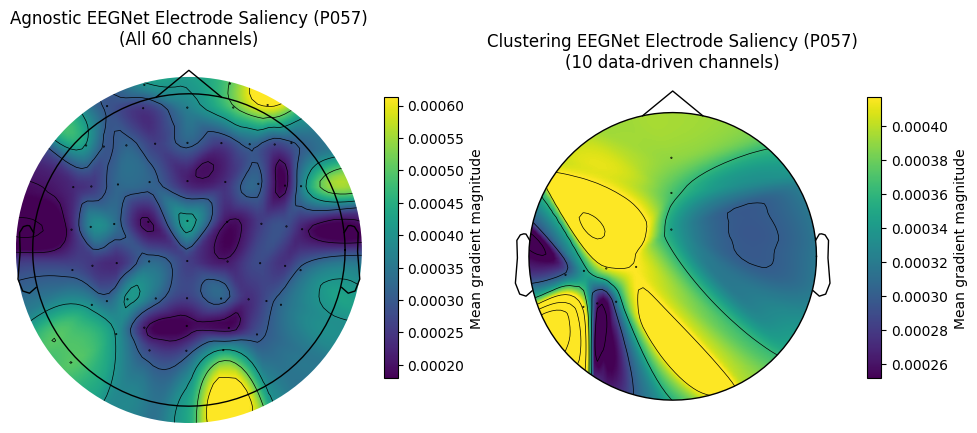

Spatial saliency topomaps saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures\saliency_spatial_comparison_P057_im_vs_ip_eegnet.png


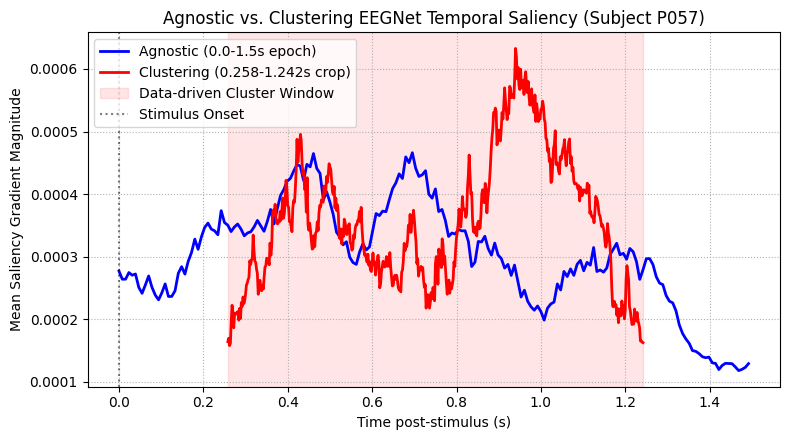

Temporal saliency plot saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures\saliency_temporal_comparison_P057_im_vs_ip_eegnet.png


In [12]:
# Extract P057 fold metrics from the cohort results and run statistical tests
metrics_agnostic = df_cohort_folds[
    (df_cohort_folds["subject"] == SUBJECT_ID) & (df_cohort_folds["model"] == "Agnostic")
].copy()
metrics_clustering = df_cohort_folds[
    (df_cohort_folds["subject"] == SUBJECT_ID) & (df_cohort_folds["model"] == "Clustering")
].copy()

acc_agn = metrics_agnostic["test_acc"].values
acc_clust = metrics_clustering["test_acc"].values
folds = list(range(1, 6))

df_folds = pd.DataFrame({"Fold": folds, "Agnostic": acc_agn, "Clustering": acc_clust})

t_stat, p_val_t = ttest_rel(acc_agn, acc_clust)
w_stat, p_val_w = wilcoxon(acc_agn, acc_clust)

print("=== P057 Cross-Validation Fold Comparison ===")
print(df_folds.to_string(index=False))
print(f"\nPaired t-test: t-statistic = {t_stat:.3f}, p-value = {p_val_t:.4f}")
print(f"Wilcoxon signed-rank test: W-statistic = {w_stat:.3f}, p-value = {p_val_w:.4f}")


# Compute cross-validated saliency maps for Agnostic & Clustering models on subject P057
device = torch.device(DEVICE)
splits = list(
    stratified_group_splits(
        y[subjects == SUBJECT_ID],
        groups=chronological_group_labels(int((subjects == SUBJECT_ID).sum())),
        n_splits=train_cfg.n_splits,
    )
)
X_sub_agn = X_agnostic[subjects == SUBJECT_ID]
X_sub_clust = X_clustering[subjects == SUBJECT_ID]
y_sub = y[subjects == SUBJECT_ID]

agn_saliencies = []
clust_saliencies = []

for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
    _, X_test_clust = standardize_train_test(X_sub_clust[train_idx], X_sub_clust[test_idx])
    y_test = y_sub[test_idx]

    # Filtrar només assajos Incongruents purs (classe 1) per extreure la saliència del conflicte real
    idx_class1 = y_test == 1
    if not np.any(idx_class1):
        continue

    X_test_agn_c1 = X_test_agn[idx_class1]
    X_test_clust_c1 = X_test_clust[idx_class1]

    # 1. Agnostic model saliency
    model_agn = make_model_agnostic().to(device)
    model_agn.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_agnostic_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device),
        strict=False,
    )
    model_agn.eval()

    X_tensor_agn = torch.from_numpy(X_test_agn_c1).to(device)
    X_tensor_agn.requires_grad_()

    logits_agn = model_agn(X_tensor_agn)
    probs_agn = torch.softmax(logits_agn, dim=1)
    score_agn = probs_agn[:, 1].sum()

    model_agn.zero_grad()
    score_agn.backward()

    saliency_agn = X_tensor_agn.grad.abs().cpu().numpy()
    agn_saliencies.append(saliency_agn.mean(axis=0))  # Mitjana dels assajos de test d'aquest fold

    # 2. Clustering model saliency
    model_clust = make_model_clustering().to(device)
    model_clust.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_clustering_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device),
        strict=False,
    )
    model_clust.eval()

    X_tensor_clust = torch.from_numpy(X_test_clust_c1).to(device)
    X_tensor_clust.requires_grad_()

    logits_clust = model_clust(X_tensor_clust)
    probs_clust = torch.softmax(logits_clust, dim=1)
    score_clust = probs_clust[:, 1].sum()

    model_clust.zero_grad()
    score_clust.backward()

    saliency_clust = X_tensor_clust.grad.abs().cpu().numpy()
    clust_saliencies.append(saliency_clust.mean(axis=0))  # Mitjana dels assajos de test d'aquest fold

# Average cross-validated saliency maps across folds
saliency_agn_p057 = np.mean(agn_saliencies, axis=0)  # Shape: (n_channels_agnostic, n_times_agnostic)
saliency_clust_p057 = np.mean(clust_saliencies, axis=0)  # Shape: (n_channels_clustering, n_times_clustering)
print("Saliency maps successfully computed for P057!")


# Plot P057 Spatial Saliency (topomaps)
spatial_imp_agn = np.mean(saliency_agn_p057, axis=1)
spatial_imp_clust = np.mean(saliency_clust_p057, axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
montage = mne.channels.make_standard_montage("standard_1005")

info_agn = mne.create_info(ch_names=ch_names_agnostic, sfreq=128.0, ch_types="eeg")
info_agn.set_montage(montage, on_missing="ignore")
vmin_agn = float(np.min(spatial_imp_agn))
vmax_agn = float(np.max(spatial_imp_agn))
im1, _ = mne.viz.plot_topomap(
    spatial_imp_agn,
    info_agn,
    axes=ax1,
    cmap="viridis",
    vlim=(vmin_agn, vmax_agn),
    show=False,
)
ax1.set_title("Agnostic EEGNet Electrode Saliency (P057)\n(All 60 channels)")
fig.colorbar(im1, ax=ax1, shrink=0.6, label="Mean gradient magnitude")

info_clust = mne.create_info(ch_names=ch_names_clustering, sfreq=128.0, ch_types="eeg")
info_clust.set_montage(montage, on_missing="ignore")
vmin_clust = float(np.min(spatial_imp_clust))
vmax_clust = float(np.max(spatial_imp_clust))
im2, _ = mne.viz.plot_topomap(
    spatial_imp_clust,
    info_clust,
    axes=ax2,
    cmap="viridis",
    vlim=(vmin_clust, vmax_clust),
    show=False,
)
ax2.set_title(f"Clustering EEGNet Electrode Saliency (P057)\n({len(ch_names_clustering)} data-driven channels)")
fig.colorbar(im2, ax=ax2, shrink=0.6, label="Mean gradient magnitude")

plt.tight_layout()
spatial_saliency_plot_path = paths.figures_dir / f"saliency_spatial_comparison_P057_{TASK_TAG}.png"
plt.savefig(spatial_saliency_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Spatial saliency topomaps saved to: {spatial_saliency_plot_path}")


# Plot P057 Temporal Saliency (profiles)
temporal_imp_agn = np.mean(saliency_agn_p057, axis=0)
temporal_imp_clust = np.mean(saliency_clust_p057, axis=0)

times_agn = times
times_clust = dataset_clustering.times

plt.figure(figsize=(8, 4.5))
plt.plot(times_agn, temporal_imp_agn, label="Agnostic (0.0-1.5s epoch)", color="blue", linewidth=2)
plt.plot(
    times_clust,
    temporal_imp_clust,
    label=f"Clustering ({tmin_crop:.3f}-{tmax_crop:.3f}s crop)",
    color="red",
    linewidth=2,
)
plt.axvspan(tmin_crop, tmax_crop, color="red", alpha=0.1, label="Data-driven Cluster Window")
plt.axvline(0.0, color="black", alpha=0.5, linestyle=":", label="Stimulus Onset")
plt.title("Agnostic vs. Clustering EEGNet Temporal Saliency (Subject P057)")
plt.xlabel("Time post-stimulus (s)")
plt.ylabel("Mean Saliency Gradient Magnitude")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()

temporal_saliency_plot_path = paths.figures_dir / f"saliency_temporal_comparison_P057_{TASK_TAG}.png"
plt.savefig(temporal_saliency_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Temporal saliency plot saved to: {temporal_saliency_plot_path}")

### 5.3 Spectral Profiles of Internal Temporal Filters

We extract the weights from the first convolutional layer (`conv_temporal`, dimensions $F1=8$ filters of size $1\times64$) of the Agnostic EEGNet models trained on subject `P057` across all 5 cross-validation folds. We apply a Fast Fourier Transform (FFT) to each temporal filter independently to visualize their spectral templates and verify whether the model naturally aligns itself to standard EEG oscillations like **theta (5–7 Hz)** or **alpha (8–12 Hz)**.

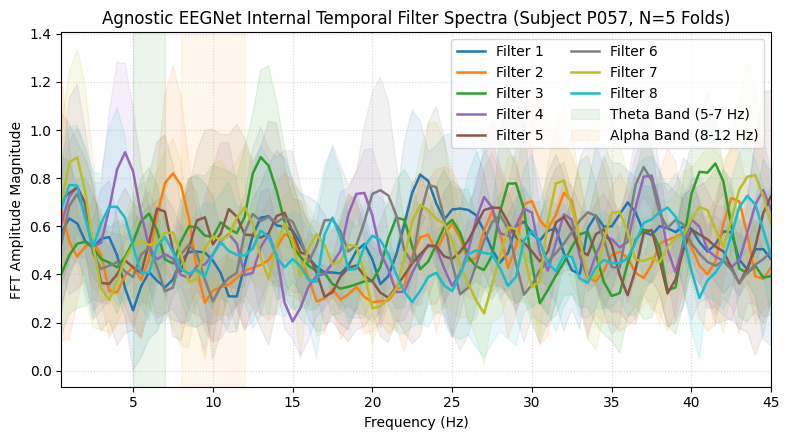

Filter spectral profiles saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures\eegnet_filter_spectra_im_vs_ip_eegnet.png


In [13]:
# Compute and plot spectral profiles of EEGNet internal temporal filters (conv_temporal layer)
F1 = 8
kernel_length = 64
sfreq = 128.0
n_fft = 256

all_fft_amps = []
for fold in range(1, 6):
    weights_path = paths.cache_dir / f"{TASK_TAG}_agnostic_sub{SUBJECT_ID}_fold{fold}.pt"
    if weights_path.exists():
        model = make_model_agnostic()
        model.load_state_dict(torch.load(weights_path, map_location="cpu"), strict=False)
        w = model.block1[0].weight.detach().numpy()  # Shape: (F1, 1, 1, kernel_length)
        w_filters = np.squeeze(w)  # Shape: (F1, kernel_length)

        fold_fft_amps = []
        for filt_idx in range(F1):
            filt_w = w_filters[filt_idx]
            fft_vals = np.fft.rfft(filt_w, n=n_fft)
            fft_amps = np.abs(fft_vals)
            fold_fft_amps.append(fft_amps)
        all_fft_amps.append(fold_fft_amps)

if all_fft_amps:
    all_fft_amps = np.array(all_fft_amps)  # Shape: (n_folds, F1, n_fft_bins)
    freqs = np.fft.rfftfreq(n_fft, d=1.0 / sfreq)
    mean_fft_amps = np.mean(all_fft_amps, axis=0)  # Shape: (F1, n_fft_bins)
    std_fft_amps = np.std(all_fft_amps, axis=0)  # Shape: (F1, n_fft_bins)

    plt.figure(figsize=(8, 4.5))
    colors = plt.cm.tab10(np.linspace(0, 1, F1))

    for filt_idx in range(F1):
        plt.plot(freqs, mean_fft_amps[filt_idx], label=f"Filter {filt_idx+1}", color=colors[filt_idx], linewidth=1.8)
        plt.fill_between(
            freqs,
            np.maximum(0, mean_fft_amps[filt_idx] - std_fft_amps[filt_idx]),
            mean_fft_amps[filt_idx] + std_fft_amps[filt_idx],
            color=colors[filt_idx],
            alpha=0.1,
        )

    # Highlight Theta (5-7 Hz) and Alpha (8-12 Hz) bands
    plt.axvspan(5.0, 7.0, color="green", alpha=0.08, label="Theta Band (5-7 Hz)")
    plt.axvspan(8.0, 12.0, color="orange", alpha=0.08, label="Alpha Band (8-12 Hz)")

    plt.title(f"Agnostic EEGNet Internal Temporal Filter Spectra (Subject {SUBJECT_ID}, N=5 Folds)")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("FFT Amplitude Magnitude")
    plt.xlim(0.5, 45.0)
    plt.grid(True, linestyle=":", alpha=0.5)
    plt.legend(ncol=2, loc="upper right")
    plt.tight_layout()

    filter_spectra_path = paths.figures_dir / f"eegnet_filter_spectra_{TASK_TAG}.png"
    plt.savefig(filter_spectra_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Filter spectral profiles saved to: {filter_spectra_path}")
else:
    print("Warning: Could not find regularized weights in cache to compute filter spectra.")

=== Paired Statistical Comparison (Agnostic vs Clustering Accuracy) ===
Paired t-test: t-statistic = 0.609, p-value = 0.5475
Wilcoxon signed-rank test: W-statistic = 190.000, p-value = 0.5647


C:\Users\nils\AppData\Local\Temp\ipykernel_117200\2111038945.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_melted, x="Model", y="Accuracy", palette=["skyblue", "lightcoral"], width=0.5)


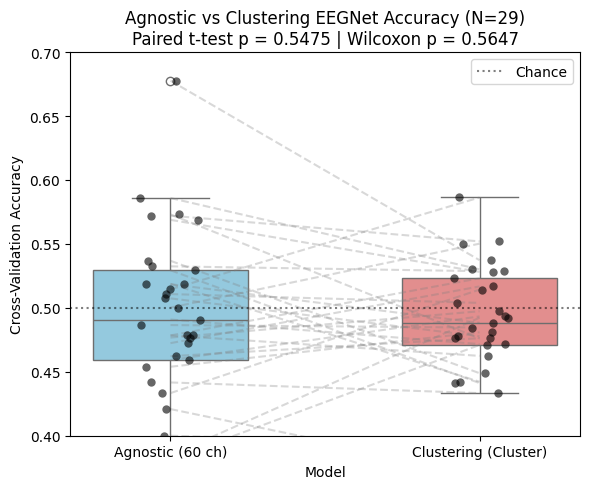

Comparison plot saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures\cohort_accuracy_comparison_im_vs_ip_eegnet.png


In [14]:
# Plot Agnostic vs Clustering accuracy comparison across subjects and run paired t-test
# Statistical tests
t_stat, p_val_t = ttest_rel(df_cohort["agnostic_acc"], df_cohort["clustering_acc"])
w_stat, p_val_w = wilcoxon(df_cohort["agnostic_acc"], df_cohort["clustering_acc"])

print("=== Paired Statistical Comparison (Agnostic vs Clustering Accuracy) ===")
print(f"Paired t-test: t-statistic = {t_stat:.3f}, p-value = {p_val_t:.4f}")
print(f"Wilcoxon signed-rank test: W-statistic = {w_stat:.3f}, p-value = {p_val_w:.4f}")

# Plot boxplot / stripplot
df_melted = df_cohort.melt(
    id_vars="subject", value_vars=["agnostic_acc", "clustering_acc"], var_name="Model", value_name="Accuracy"
)
df_melted["Model"] = df_melted["Model"].map(
    {"agnostic_acc": "Agnostic (60 ch)", "clustering_acc": "Clustering (Cluster)"}
)

plt.figure(figsize=(6, 5))
sns.boxplot(data=df_melted, x="Model", y="Accuracy", palette=["skyblue", "lightcoral"], width=0.5)
sns.stripplot(data=df_melted, x="Model", y="Accuracy", color="black", alpha=0.6, size=6, jitter=0.1)

# Draw lines connecting the same subject
for idx, row in df_cohort.iterrows():
    plt.plot([0, 1], [row["agnostic_acc"], row["clustering_acc"]], color="gray", alpha=0.3, linestyle="--")

plt.ylim(0.4, 0.7)
plt.axhline(0.5, color="black", linestyle=":", alpha=0.5, label="Chance")
plt.title(
    f"Agnostic vs Clustering EEGNet Accuracy (N={len(df_cohort)})\n"
    f"Paired t-test p = {p_val_t:.4f} | Wilcoxon p = {p_val_w:.4f}"
)
plt.ylabel("Cross-Validation Accuracy")
plt.legend()
plt.tight_layout()

comparison_plot_path = paths.figures_dir / f"cohort_accuracy_comparison_{TASK_TAG}.png"
plt.savefig(comparison_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Comparison plot saved to: {comparison_plot_path}")

Extracting cohort test predictions across all subjects and folds...
Total Agnostic predictions aggregated: 4570
Total Clustering predictions aggregated: 4570


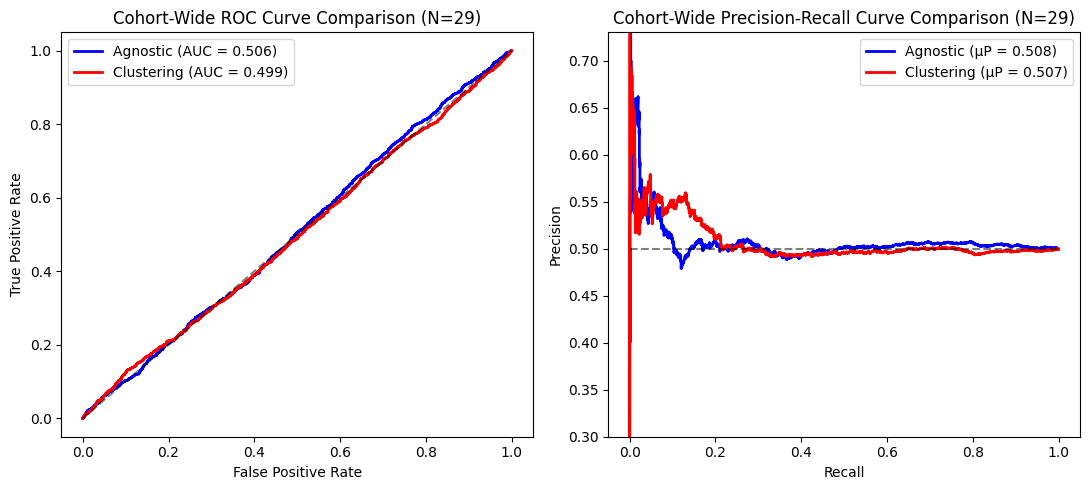

Cohort-wide ROC/PR plot saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures\cohort_roc_pr_comparison_im_vs_ip_eegnet.png


In [15]:
# Compute and plot cohort-wide aggregated ROC and PR curves for all subjects
device = torch.device(DEVICE)
agn_y_true = []
agn_probs = []
clust_y_true = []
clust_probs = []
subject_agn_trues = {}
subject_agn_probs = {}
subject_clust_trues = {}
subject_clust_probs = {}

print("Extracting cohort test predictions across all subjects and folds...")
for sub in subject_ids:
    splits = list(
        stratified_group_splits(
            y[subjects == sub],
            groups=chronological_group_labels(int((subjects == sub).sum())),
            n_splits=train_cfg.n_splits,
        )
    )
    X_sub_agn = X_agnostic[subjects == sub]
    X_sub_clust = X_clustering[subjects == sub]
    y_sub = y[subjects == sub]

    sub_agn_true = []
    sub_agn_prob = []
    sub_clust_true = []
    sub_clust_prob = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
        _, X_test_clust = standardize_train_test(X_sub_clust[train_idx], X_sub_clust[test_idx])
        y_test = y_sub[test_idx]

        # 1. Agnostic model predictions
        weights_path_agn = paths.cache_dir / f"{TASK_TAG}_agnostic_sub{sub}_fold{fold}.pt"
        if weights_path_agn.exists():
            model_agn = make_model_agnostic().to(device)
            model_agn.load_state_dict(torch.load(weights_path_agn, map_location=device), strict=False)
            model_agn.eval()
            loader_agn = build_dataloader(
                X_test_agn, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device
            )
            _, _, _, y_true_arr, p_agn = _evaluate(model_agn, loader_agn, device)
            agn_y_true.extend(y_true_arr)
            agn_probs.extend(p_agn)
            sub_agn_true.extend(y_true_arr)
            sub_agn_prob.extend(p_agn)

        # 2. Clustering model predictions
        weights_path_clust = paths.cache_dir / f"{TASK_TAG}_clustering_sub{sub}_fold{fold}.pt"
        if weights_path_clust.exists():
            model_clust = make_model_clustering().to(device)
            model_clust.load_state_dict(torch.load(weights_path_clust, map_location=device), strict=False)
            model_clust.eval()
            loader_clust = build_dataloader(
                X_test_clust, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device
            )
            _, _, _, y_true_arr, p_clust = _evaluate(model_clust, loader_clust, device)
            clust_y_true.extend(y_true_arr)
            clust_probs.extend(p_clust)
            sub_clust_true.extend(y_true_arr)
            sub_clust_prob.extend(p_clust)

    if len(sub_agn_true) > 0:
        subject_agn_trues[sub] = np.array(sub_agn_true)
        subject_agn_probs[sub] = np.array(sub_agn_prob)
    if len(sub_clust_true) > 0:
        subject_clust_trues[sub] = np.array(sub_clust_true)
        subject_clust_probs[sub] = np.array(sub_clust_prob)

agn_y_true = np.array(agn_y_true)
agn_probs = np.array(agn_probs)
clust_y_true = np.array(clust_y_true)
clust_probs = np.array(clust_probs)

print(f"Total Agnostic predictions aggregated: {len(agn_y_true)}")
print(f"Total Clustering predictions aggregated: {len(clust_y_true)}")

# Plot overlaid ROC/PR curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 5))

# ROC Curve
fpr_agn, tpr_agn, _ = roc_curve(agn_y_true, agn_probs)
fpr_clust, tpr_clust, _ = roc_curve(clust_y_true, clust_probs)
ax_roc.plot(fpr_agn, tpr_agn, label=f"Agnostic (AUC = {auc(fpr_agn, tpr_agn):.3f})", color="blue", linewidth=2)
ax_roc.plot(fpr_clust, tpr_clust, label=f"Clustering (AUC = {auc(fpr_clust, tpr_clust):.3f})", color="red", linewidth=2)
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax_roc.set_title(f"Cohort-Wide ROC Curve Comparison (N={len(subject_ids)})")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()

# PR Curve
prec_agn, rec_agn, _ = precision_recall_curve(agn_y_true, agn_probs)
prec_clust, rec_clust, _ = precision_recall_curve(clust_y_true, clust_probs)
ax_pr.plot(rec_agn, prec_agn, label=f"Agnostic (μP = {auc(rec_agn, prec_agn):.3f})", color="blue", linewidth=2)
ax_pr.plot(rec_clust, prec_clust, label=f"Clustering (μP = {auc(rec_clust, prec_clust):.3f})", color="red", linewidth=2)
ax_pr.plot([0, 1], [0.5, 0.5], "k--", alpha=0.5)
ax_pr.set_title(f"Cohort-Wide Precision-Recall Curve Comparison (N={len(subject_ids)})")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.set_ylim(0.3, 0.73)
ax_pr.legend()

plt.tight_layout()
cohort_roc_pr_path = paths.figures_dir / f"cohort_roc_pr_comparison_{TASK_TAG}.png"
plt.savefig(cohort_roc_pr_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Cohort-wide ROC/PR plot saved to: {cohort_roc_pr_path}")

### 6.3 Cohort-Wide Error Asymmetry & Class Bias Analysis

Due to the trial imbalance common in Binocular Rivalry datasets, models can develop a systematic bias towards predicting the majority class. We compute row-normalized confusion matrices (representing the true recall rate for each class) and analyze the ratio between False Positives (FP) and False Negatives (FN) to verify if the EEGNet architectures maintain genuine sensitivity to the conflict condition.

=== Agnostic Model Classification Counts & Bias ===
True Negatives (TN): 1251 | False Positives (FP): 1036
False Negatives (FN): 1255 | True Positives (TP): 1028
FP / FN Bias Ratio: 0.825 (FP >> FN indicates a bias towards predicting the Incongruent Pure class)

=== Clustering Model Classification Counts & Bias ===
True Negatives (TN): 1156 | False Positives (FP): 1131
False Negatives (FN): 1175 | True Positives (TP): 1108
FP / FN Bias Ratio: 0.963


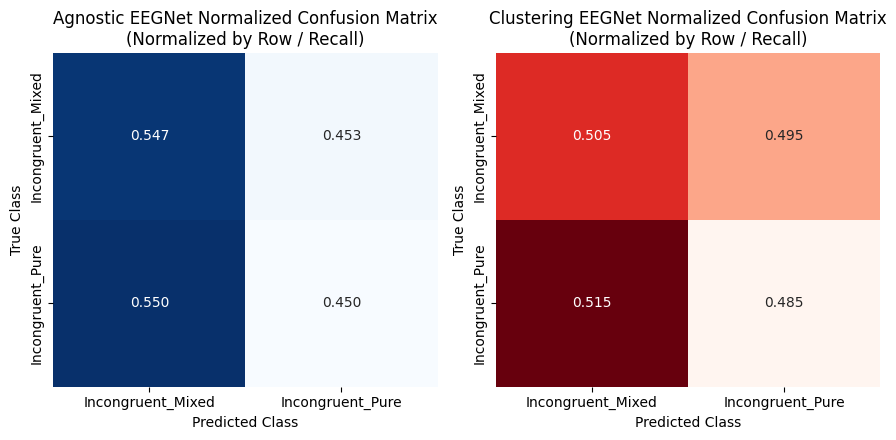

Confusion matrices saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures\cohort_confusion_matrices_im_vs_ip_eegnet.png


In [16]:
# Compute and plot row-normalized confusion matrices and error asymmetry ratios
# Calculate predictions from aggregated test probabilities (threshold at 0.5)
agn_pred = (agn_probs >= 0.5).astype(int)
clust_pred = (clust_probs >= 0.5).astype(int)

# Row-normalized confusion matrices (percentage of recall per class)
cm_agn = confusion_matrix(agn_y_true, agn_pred, normalize="true")
cm_clust = confusion_matrix(clust_y_true, clust_pred, normalize="true")

# Absolute counts for bias ratio (FP and FN)
tn_agn, fp_agn, fn_agn, tp_agn = confusion_matrix(agn_y_true, agn_pred).ravel()
tn_clust, fp_clust, fn_clust, tp_clust = confusion_matrix(clust_y_true, clust_pred).ravel()

# Bias ratio calculation (FP / FN)
ratio_agn = fp_agn / fn_agn if fn_agn > 0 else np.nan
ratio_clust = fp_clust / fn_clust if fn_clust > 0 else np.nan

print("=== Agnostic Model Classification Counts & Bias ===")
print(f"True Negatives (TN): {tn_agn} | False Positives (FP): {fp_agn}")
print(f"False Negatives (FN): {fn_agn} | True Positives (TP): {tp_agn}")
print(f"FP / FN Bias Ratio: {ratio_agn:.3f} (FP >> FN indicates a bias towards predicting the Incongruent Pure class)")

print("\n=== Clustering Model Classification Counts & Bias ===")
print(f"True Negatives (TN): {tn_clust} | False Positives (FP): {fp_clust}")
print(f"False Negatives (FN): {fn_clust} | True Positives (TP): {tp_clust}")
print(f"FP / FN Bias Ratio: {ratio_clust:.3f}")

# Plot side-by-side normalized confusion matrices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.5))
classes = [task.class_0, task.class_1]

# Agnostic
sns.heatmap(cm_agn, annot=True, fmt=".3f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax1, cbar=False)
ax1.set_title("Agnostic EEGNet Normalized Confusion Matrix\n(Normalized by Row / Recall)")
ax1.set_xlabel("Predicted Class")
ax1.set_ylabel("True Class")

# Clustering
sns.heatmap(cm_clust, annot=True, fmt=".3f", cmap="Reds", xticklabels=classes, yticklabels=classes, ax=ax2, cbar=False)
ax2.set_title("Clustering EEGNet Normalized Confusion Matrix\n(Normalized by Row / Recall)")
ax2.set_xlabel("Predicted Class")
ax2.set_ylabel("True Class")

plt.tight_layout()
cm_plot_path = paths.figures_dir / f"cohort_confusion_matrices_{TASK_TAG}.png"
plt.savefig(cm_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Confusion matrices saved to: {cm_plot_path}")

Calculating group-average spatial saliency maps (Incongruent_Pure only)...


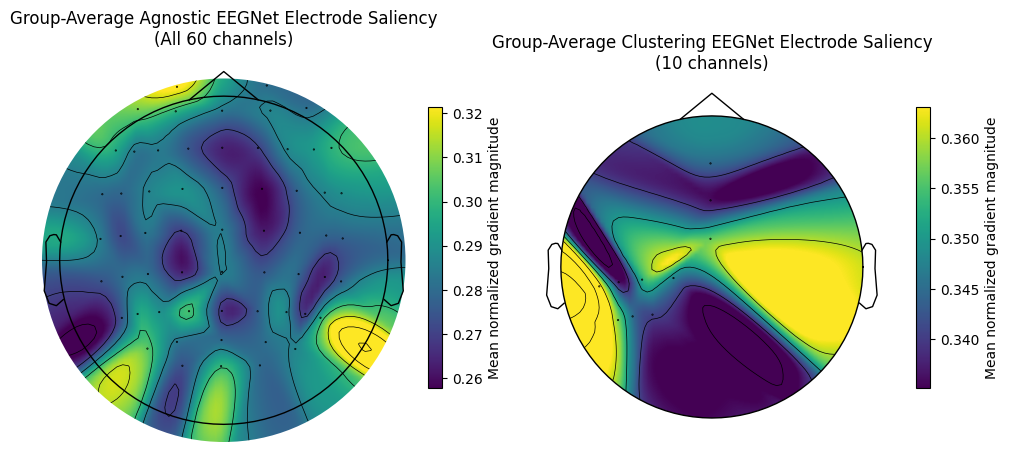

Group spatial saliency topomaps saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures\group_saliency_spatial_comparison_im_vs_ip_eegnet.png


In [17]:
# Compute and plot Group-Average Spatial Saliency (Electrode Importance) across all selected subjects
device = torch.device(DEVICE)
group_spatial_agnostic = []
group_spatial_clustering = []

print(f"Calculating group-average spatial saliency maps ({task.class_1} only)...")
for sub in subject_ids:
    splits = list(
        stratified_group_splits(
            y[subjects == sub],
            groups=chronological_group_labels(int((subjects == sub).sum())),
            n_splits=train_cfg.n_splits,
        )
    )
    X_sub_agn = X_agnostic[subjects == sub]
    X_sub_clust = X_clustering[subjects == sub]
    y_sub = y[subjects == sub]

    sub_agn_saliencies = []
    sub_clust_saliencies = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
        _, X_test_clust = standardize_train_test(X_sub_clust[train_idx], X_sub_clust[test_idx])
        y_test = y_sub[test_idx]

        # Filter only pure Incongruent trials (IP) to extract the saliency of conflict processing
        idx_class1 = y_test == 1
        if not np.any(idx_class1):
            continue

        X_test_agn_c1 = X_test_agn[idx_class1]
        X_test_clust_c1 = X_test_clust[idx_class1]

        # 1. Agnostic model saliency
        weights_path_agn = paths.cache_dir / f"{TASK_TAG}_agnostic_sub{sub}_fold{fold}.pt"
        if weights_path_agn.exists():
            model_agn = make_model_agnostic().to(device)
            model_agn.load_state_dict(torch.load(weights_path_agn, map_location=device), strict=False)
            model_agn.eval()

            X_tensor_agn = torch.from_numpy(X_test_agn_c1).to(device)
            X_tensor_agn.requires_grad_()

            logits_agn = model_agn(X_tensor_agn)
            probs_agn = torch.softmax(logits_agn, dim=1)
            score_agn = probs_agn[:, 1].sum()

            model_agn.zero_grad()
            score_agn.backward()

            saliency_agn = X_tensor_agn.grad.abs().cpu().numpy()
            sub_agn_saliencies.append(saliency_agn.mean(axis=0))

        # 2. Clustering model saliency
        weights_path_clust = paths.cache_dir / f"{TASK_TAG}_clustering_sub{sub}_fold{fold}.pt"
        if weights_path_clust.exists():
            model_clust = make_model_clustering().to(device)
            model_clust.load_state_dict(torch.load(weights_path_clust, map_location=device), strict=False)
            model_clust.eval()

            X_tensor_clust = torch.from_numpy(X_test_clust_c1).to(device)
            X_tensor_clust.requires_grad_()

            logits_clust = model_clust(X_tensor_clust)
            probs_clust = torch.softmax(logits_clust, dim=1)
            score_clust = probs_clust[:, 1].sum()

            model_clust.zero_grad()
            score_clust.backward()

            saliency_clust = X_tensor_clust.grad.abs().cpu().numpy()
            sub_clust_saliencies.append(saliency_clust.mean(axis=0))

    if sub_agn_saliencies:
        sub_mean_saliencies = np.mean(sub_agn_saliencies, axis=0)
        sub_mean_norm_saliencies = (
            sub_mean_saliencies / np.max(sub_mean_saliencies)
            if np.max(sub_mean_saliencies) > 0
            else sub_mean_saliencies
        )
        group_spatial_agnostic.append(np.mean(sub_mean_norm_saliencies, axis=1))
    if sub_clust_saliencies:
        sub_mean_clust = np.mean(sub_clust_saliencies, axis=0)
        sub_mean_norm_clust = sub_mean_clust / np.max(sub_mean_clust) if np.max(sub_mean_clust) > 0 else sub_mean_clust
        group_spatial_clustering.append(np.mean(sub_mean_norm_clust, axis=1))

group_avg_spatial_agn = np.mean(group_spatial_agnostic, axis=0)
group_avg_spatial_clust = np.mean(group_spatial_clustering, axis=0)

# Plot side-by-side group topomaps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
montage = mne.channels.make_standard_montage("standard_1005")

# Agnostic
info_agn = mne.create_info(ch_names=ch_names_agnostic, sfreq=128.0, ch_types="eeg")
info_agn.set_montage(montage, on_missing="ignore")
vmin_agn = float(np.min(group_avg_spatial_agn))
vmax_agn = float(np.max(group_avg_spatial_agn))
im1, _ = mne.viz.plot_topomap(
    group_avg_spatial_agn,
    info_agn,
    axes=ax1,
    cmap="viridis",
    vlim=(vmin_agn, vmax_agn),
    show=False,
)
ax1.set_title("Group-Average Agnostic EEGNet Electrode Saliency\n(All 60 channels)")
fig.colorbar(im1, ax=ax1, shrink=0.6, label="Mean normalized gradient magnitude")

# Clustering
info_foc = mne.create_info(ch_names=ch_names_clustering, sfreq=128.0, ch_types="eeg")
info_foc.set_montage(montage, on_missing="ignore")
vmin_clust = float(np.min(group_avg_spatial_clust))
vmax_clust = float(np.max(group_avg_spatial_clust))
im2, _ = mne.viz.plot_topomap(
    group_avg_spatial_clust,
    info_foc,
    axes=ax2,
    cmap="viridis",
    vlim=(vmin_clust, vmax_clust),
    show=False,
)
ax2.set_title(f"Group-Average Clustering EEGNet Electrode Saliency\n({len(ch_names_clustering)} channels)")
fig.colorbar(im2, ax=ax2, shrink=0.6, label="Mean normalized gradient magnitude")

plt.tight_layout()
group_spatial_plot_path = paths.figures_dir / f"group_saliency_spatial_comparison_{TASK_TAG}.png"
plt.savefig(group_spatial_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Group spatial saliency topomaps saved to: {group_spatial_plot_path}")

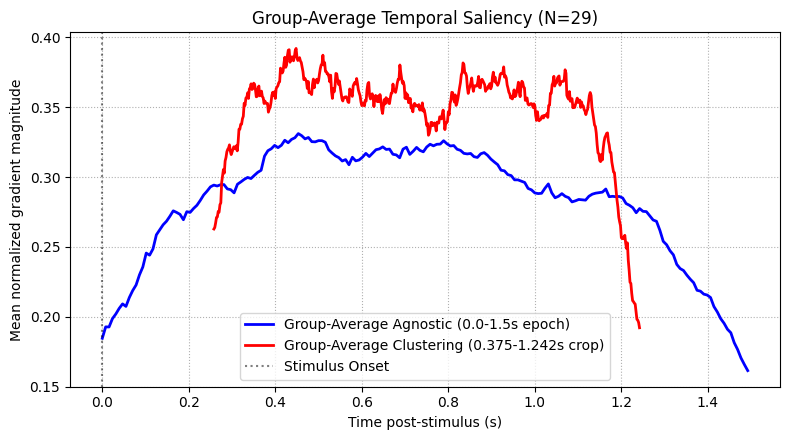

Group temporal saliency plot saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures\group_saliency_temporal_comparison_im_vs_ip_eegnet.png


In [18]:
# Compute and plot Group-Average Temporal Saliency (Time-Window Importance) across all selected subjects
group_temporal_agnostic = []
group_temporal_clustering = []

for sub in subject_ids:
    splits = list(
        stratified_group_splits(
            y[subjects == sub],
            groups=chronological_group_labels(int((subjects == sub).sum())),
            n_splits=train_cfg.n_splits,
        )
    )
    X_sub_agn = X_agnostic[subjects == sub]
    X_sub_clust = X_clustering[subjects == sub]
    y_sub = y[subjects == sub]

    sub_agn_saliencies = []
    sub_clust_saliencies = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
        _, X_test_clust = standardize_train_test(X_sub_clust[train_idx], X_sub_clust[test_idx])
        y_test = y_sub[test_idx]

        # Filter only pure Incongruent trials (IP) to extract the saliency of conflict processing
        idx_class1 = y_test == 1
        if not np.any(idx_class1):
            continue

        X_test_agn_c1 = X_test_agn[idx_class1]
        X_test_clust_c1 = X_test_clust[idx_class1]

        # 1. Agnostic model saliency
        weights_path_agn = paths.cache_dir / f"{TASK_TAG}_agnostic_sub{sub}_fold{fold}.pt"
        if weights_path_agn.exists():
            model_agn = make_model_agnostic().to(device)
            model_agn.load_state_dict(torch.load(weights_path_agn, map_location=device), strict=False)
            model_agn.eval()

            X_tensor_agn = torch.from_numpy(X_test_agn_c1).to(device)
            X_tensor_agn.requires_grad_()

            logits_agn = model_agn(X_tensor_agn)
            probs_agn = torch.softmax(logits_agn, dim=1)
            score_agn = probs_agn[:, 1].sum()

            model_agn.zero_grad()
            score_agn.backward()

            saliency_agn = X_tensor_agn.grad.abs().cpu().numpy()
            sub_agn_saliencies.append(saliency_agn.mean(axis=0))

        # 2. Clustering model saliency
        weights_path_clust = paths.cache_dir / f"{TASK_TAG}_clustering_sub{sub}_fold{fold}.pt"
        if weights_path_clust.exists():
            model_clust = make_model_clustering().to(device)
            model_clust.load_state_dict(torch.load(weights_path_clust, map_location=device), strict=False)
            model_clust.eval()

            X_tensor_clust = torch.from_numpy(X_test_clust_c1).to(device)
            X_tensor_clust.requires_grad_()

            logits_clust = model_clust(X_tensor_clust)
            probs_clust = torch.softmax(logits_clust, dim=1)
            score_clust = probs_clust[:, 1].sum()

            model_clust.zero_grad()
            score_clust.backward()

            saliency_clust = X_tensor_clust.grad.abs().cpu().numpy()
            sub_clust_saliencies.append(saliency_clust.mean(axis=0))

    if sub_agn_saliencies:
        group_temporal_agnostic_mean = np.mean(sub_agn_saliencies, axis=0)
        group_temporal_agnostic_norm = (
            group_temporal_agnostic_mean / np.max(group_temporal_agnostic_mean)
            if np.max(group_temporal_agnostic_mean) > 0
            else group_temporal_agnostic_mean
        )
        group_temporal_agnostic.append(np.mean(group_temporal_agnostic_norm, axis=0))
    if sub_clust_saliencies:
        group_temporal_clust_mean = np.mean(sub_clust_saliencies, axis=0)
        group_temporal_clust_norm = (
            group_temporal_clust_mean / np.max(group_temporal_clust_mean)
            if np.max(group_temporal_clust_mean) > 0
            else group_temporal_clust_mean
        )
        group_temporal_clustering.append(np.mean(group_temporal_clust_norm, axis=0))

group_avg_temp_agn = np.mean(group_temporal_agnostic, axis=0)
group_avg_temp_clust = np.mean(group_temporal_clustering, axis=0)

# Plot temporal saliency profiles
plt.figure(figsize=(8, 4.5))
plt.plot(times, group_avg_temp_agn, label="Group-Average Agnostic (0.0-1.5s epoch)", color="blue", linewidth=2)
plt.plot(
    dataset_clustering.times,
    group_avg_temp_clust,
    label="Group-Average Clustering (0.375-1.242s crop)",
    color="red",
    linewidth=2,
)

plt.axvline(0.0, color="black", alpha=0.5, linestyle=":", label="Stimulus Onset")
plt.title(f"Group-Average Temporal Saliency (N={len(group_temporal_agnostic)})")
plt.xlabel("Time post-stimulus (s)")
plt.ylabel("Mean normalized gradient magnitude")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()

group_temporal_saliency_plot_path = paths.figures_dir / f"group_saliency_temporal_comparison_{TASK_TAG}.png"
plt.savefig(group_temporal_saliency_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Group temporal saliency plot saved to: {group_temporal_saliency_plot_path}")

### 6.6 Group-Level Statistical Differential Saliency Map

To identify spatial regions that are consistently more important for conflict trials than control trials across the entire cohort, we compute the differential saliency map for each subject: $\text{Saliency(IP)} - \text{Saliency(C)}$. We then run a **one-sample t-test** across the selected subjects for each electrode, correcting for multiple comparisons via **Benjamini-Hochberg (FDR)**. We plot the t-statistics and mask the significant channels ($p_{\text{FDR}} < 0.05$) to verify convergence with Drew et al.'s findings (checking whether the learned saliency converges with the expected fronto-medial theta and posterior alpha patterns).

Computing differential saliency maps (Incongruent_Pure - Incongruent_Mixed) for all subjects...


FDR Significant Channels (p_FDR < 0.05):
[]


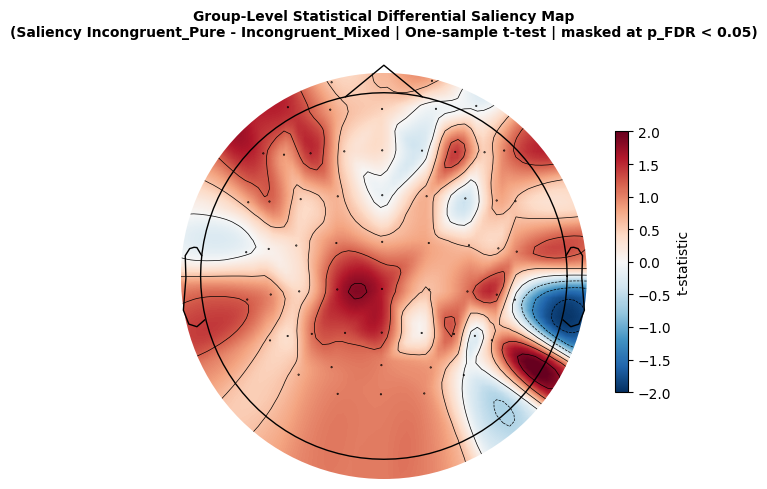

Differential saliency topomap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures\group_saliency_differential_topomap_im_vs_ip_eegnet.png


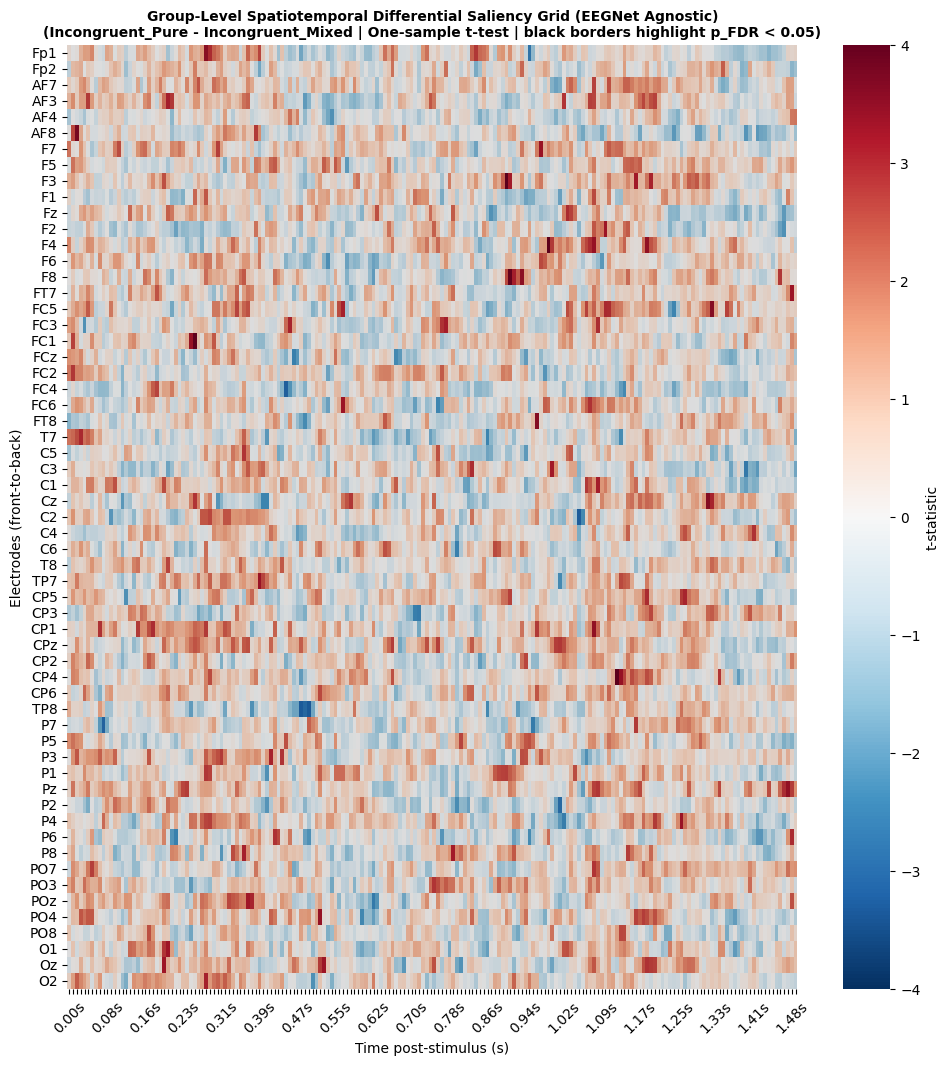

Differential saliency heatmap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\figures\group_saliency_differential_heatmap_im_vs_ip_eegnet.png


In [19]:
# Compute and plot Group-Level Statistical Differential Saliency Map and Grid Heatmap
device = torch.device(DEVICE)
sub_diff_spatial = []
sub_diff_spatiotemporal = []

print(f"Computing differential saliency maps ({task.class_1} - {task.class_0}) for all subjects...")
for sub in subject_ids:
    splits = list(
        stratified_group_splits(
            y[subjects == sub],
            groups=chronological_group_labels(int((subjects == sub).sum())),
            n_splits=train_cfg.n_splits,
        )
    )
    X_sub_agn = X_agnostic[subjects == sub]
    y_sub = y[subjects == sub]

    sub_c1_saliencies = []
    sub_c0_saliencies = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
        y_test = y_sub[test_idx]

        weights_path_agn = paths.cache_dir / f"{TASK_TAG}_agnostic_sub{sub}_fold{fold}.pt"
        if weights_path_agn.exists():
            model_agn = make_model_agnostic().to(device)
            model_agn.load_state_dict(torch.load(weights_path_agn, map_location=device), strict=False)
            model_agn.eval()

            # IP (Incongruent Pure)
            idx_c1 = y_test == 1
            if np.any(idx_c1):
                X_tensor_c1 = torch.from_numpy(X_test_agn[idx_c1]).to(device)
                X_tensor_c1.requires_grad_()
                logits = model_agn(X_tensor_c1)
                probs = torch.softmax(logits, dim=1)
                score = probs[:, 1].sum()
                model_agn.zero_grad()
                score.backward()
                saliency_c1 = X_tensor_c1.grad.abs().cpu().numpy()
                sub_c1_saliencies.append(saliency_c1.mean(axis=0))

            # C (Incongruent Mirrored)
            idx_c0 = y_test == 0
            if np.any(idx_c0):
                X_tensor_c0 = torch.from_numpy(X_test_agn[idx_c0]).to(device)
                X_tensor_c0.requires_grad_()
                logits = model_agn(X_tensor_c0)
                probs = torch.softmax(logits, dim=1)
                score = probs[:, 0].sum()
                model_agn.zero_grad()
                score.backward()
                saliency_c0 = X_tensor_c0.grad.abs().cpu().numpy()
                sub_c0_saliencies.append(saliency_c0.mean(axis=0))

    if sub_c1_saliencies and sub_c0_saliencies:
        mean_c1 = np.mean(sub_c1_saliencies, axis=0)
        mean_c0 = np.mean(sub_c0_saliencies, axis=0)

        # Max-normalize each subject's map to prevent raw scale imbalances
        mean_c1_norm = mean_c1 / np.max(mean_c1) if np.max(mean_c1) > 0 else mean_c1
        mean_c0_norm = mean_c0 / np.max(mean_c0) if np.max(mean_c0) > 0 else mean_c0

        diff = mean_c1_norm - mean_c0_norm
        spatial_diff = np.mean(diff, axis=1)  # Average over time dimension, shape: (n_channels,)
        sub_diff_spatial.append(spatial_diff)
        sub_diff_spatiotemporal.append(diff)

if sub_diff_spatial:
    sub_diff_spatial = np.array(sub_diff_spatial)  # Shape: (n_subjects, n_channels)
    sub_diff_spatiotemporal = np.array(sub_diff_spatiotemporal)  # Shape: (n_subjects, n_channels, n_times)
    n_channels = sub_diff_spatial.shape[1]

    t_stats = np.zeros(n_channels)
    p_vals = np.zeros(n_channels)

    for ch in range(n_channels):
        t_stat, p_val = ttest_1samp(sub_diff_spatial[:, ch], 0.0)
        t_stats[ch] = t_stat
        p_vals[ch] = p_val

    # FDR correction for spatial topomap
    reject, p_vals_fdr = fdr_correction(p_vals, alpha=0.05, method="indep")

    print(f"FDR Significant Channels (p_FDR < 0.05):")
    sig_channels = [ch_names_agnostic[i] for i, val in enumerate(reject) if val]
    print(sig_channels)

    # Plot 1: t-stats topomap with masked significant channels
    fig, ax = plt.subplots(figsize=(6, 5))
    montage = mne.channels.make_standard_montage("standard_1005")
    info_agn = mne.create_info(ch_names=ch_names_agnostic, sfreq=128.0, ch_types="eeg")
    info_agn.set_montage(montage, on_missing="ignore")

    im, _ = mne.viz.plot_topomap(
        t_stats,
        info_agn,
        axes=ax,
        mask=reject,
        mask_params=dict(marker="o", markerfacecolor="black", markersize=6, markeredgecolor="black"),
        cmap="RdBu_r",
        vlim=(-2.0, 2.0),
        show=False,
    )

    ax.set_title(
        "Group-Level Statistical Differential Saliency Map\n"
        f"(Saliency {task.class_1} - {task.class_0} | One-sample t-test | masked at p_FDR < 0.05)",
        fontsize=10,
        fontweight="bold",
    )
    fig.colorbar(im, ax=ax, shrink=0.6, label="t-statistic")
    plt.tight_layout()

    diff_saliency_plot_path = paths.figures_dir / f"group_saliency_differential_topomap_{TASK_TAG}.png"
    plt.savefig(diff_saliency_plot_path, dpi=220, bbox_inches="tight")
    plt.show()
    print(f"Differential saliency topomap saved to: {diff_saliency_plot_path}")

    # Plot 2: Spatiotemporal Grid Heatmap
    # Run t-test and FDR correction for spatiotemporal grid
    t_grid, p_grid = ttest_1samp(sub_diff_spatiotemporal, 0.0, axis=0)
    reject_grid, _ = fdr_correction(p_grid, alpha=0.05, method="indep")

    CHANNEL_ORDER = [
        "Fp1",
        "Fp2",
        "AF7",
        "AF3",
        "AF4",
        "AF8",
        "F7",
        "F5",
        "F3",
        "F1",
        "Fz",
        "F2",
        "F4",
        "F6",
        "F8",
        "FT7",
        "FC5",
        "FC3",
        "FC1",
        "FCz",
        "FC2",
        "FC4",
        "FC6",
        "FT8",
        "T7",
        "C5",
        "C3",
        "C1",
        "Cz",
        "C2",
        "C4",
        "C6",
        "T8",
        "TP7",
        "CP5",
        "CP3",
        "CP1",
        "CPz",
        "CP2",
        "CP4",
        "CP6",
        "TP8",
        "P7",
        "P5",
        "P3",
        "P1",
        "Pz",
        "P2",
        "P4",
        "P6",
        "P8",
        "PO7",
        "PO3",
        "POz",
        "PO4",
        "PO8",
        "O1",
        "Oz",
        "O2",
    ]
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names_agnostic)}
    present_order = [ch for ch in CHANNEL_ORDER if ch in ch_to_idx]
    ordered_idx = [ch_to_idx[ch] for ch in present_order]

    t_vals_ordered = t_grid[ordered_idx, :]
    sig_mask_ordered = reject_grid[ordered_idx, :]

    fig_height = len(present_order) * 0.14 + 2.5
    fig_hm, ax_hm = plt.subplots(figsize=(10, fig_height))

    vmax = float(np.percentile(np.abs(t_vals_ordered), 95))
    if vmax == 0:
        vmax = 1.0

    xticklabels = [f"{t:.2f}s" if idx % 10 == 0 else "" for idx, t in enumerate(times)]

    sns.heatmap(
        t_vals_ordered,
        ax=ax_hm,
        cmap="RdBu_r",
        center=0.0,
        vmin=-4,
        vmax=4,
        xticklabels=xticklabels,
        yticklabels=present_order,
        cbar_kws={"label": "t-statistic"},
    )

    for i in range(t_vals_ordered.shape[0]):
        for j in range(t_vals_ordered.shape[1]):
            if sig_mask_ordered[i, j]:
                ax_hm.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=1.2))
            else:
                ax_hm.add_patch(patches.Rectangle((j, i), 1, 1, fill=True, color="black", alpha=0.1, linewidth=0))

    ax_hm.set_title(
        "Group-Level Spatiotemporal Differential Saliency Grid (EEGNet Agnostic)\n"
        f"({task.class_1} - {task.class_0} | One-sample t-test | black borders highlight p_FDR < 0.05)",
        fontsize=10,
        fontweight="bold",
    )
    ax_hm.set_xlabel("Time post-stimulus (s)")
    ax_hm.set_ylabel("Electrodes (front-to-back)")
    ax_hm.tick_params(axis="x", rotation=45)
    plt.tight_layout()

    diff_saliency_heatmap_path = paths.figures_dir / f"group_saliency_differential_heatmap_{TASK_TAG}.png"
    plt.savefig(diff_saliency_heatmap_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Differential saliency heatmap saved to: {diff_saliency_heatmap_path}")
else:
    print("Warning: No differential saliency maps computed.")

## 7. Cohort-Wide Averaged Classification Reports

We calculate subject-wise classification reports and average precision, recall, and F1 across all selected subjects for both EEGNet variants. The all-fold out-of-fold report is the primary result under the current `StratifiedGroupKFold` strategy.

The optional fold-specific block below is kept only as a diagnostic/cache-continuity view. It should not be interpreted as a fairer or more realistic Fold 5 estimate, because folds are no longer chronological walk-forward splits with increasing training size.


In [20]:
# 1. Standard aggregated reports (all folds combined)
reports_agn = []
for sub in subject_agn_trues.keys():
    sub_y_true = subject_agn_trues[sub]
    sub_y_pred = (subject_agn_probs[sub] >= 0.5).astype(int)
    rep = classification_report(
        sub_y_true, sub_y_pred, target_names=[task.class_0, task.class_1], output_dict=True, zero_division=0.0
    )
    reports_agn.append(rep)

avg_report_agn = {}
metrics_keys = ["precision", "recall", "f1-score", "support"]
class_keys = [task.class_0, task.class_1, "macro avg", "weighted avg"]
for ck in class_keys:
    avg_report_agn[ck] = {}
    for mk in metrics_keys:
        avg_report_agn[ck][mk] = np.mean([r[ck][mk] for r in reports_agn])
avg_report_agn["accuracy"] = np.mean([r["accuracy"] for r in reports_agn])

reports_clust = []
for sub in subject_clust_trues.keys():
    sub_y_true = subject_clust_trues[sub]
    sub_y_pred = (subject_clust_probs[sub] >= 0.5).astype(int)
    rep = classification_report(
        sub_y_true, sub_y_pred, target_names=[task.class_0, task.class_1], output_dict=True, zero_division=0.0
    )
    reports_clust.append(rep)

avg_report_clust = {}
for ck in class_keys:
    avg_report_clust[ck] = {}
    for mk in metrics_keys:
        avg_report_clust[ck][mk] = np.mean([r[ck][mk] for r in reports_clust])
avg_report_clust["accuracy"] = np.mean([r["accuracy"] for r in reports_clust])

print("==========================================================")
print("=== AVERAGE CLASSIFICATION REPORT (ALL FOLDS COMBINED) ===")
print("==========================================================")
print("--- EEGNet Agnostic ---")
print(pd.DataFrame(avg_report_agn).T)
print("\n--- EEGNet Clustering ---")
print(pd.DataFrame(avg_report_clust).T)

=== AVERAGE CLASSIFICATION REPORT (ALL FOLDS COMBINED) ===
--- EEGNet Agnostic ---
                   precision    recall  f1-score     support
Incongruent_Mixed   0.496061  0.541313  0.514304   78.862069
Incongruent_Pure    0.492569  0.448614  0.465118   78.724138
macro avg           0.494315  0.494963  0.489711  157.586207
weighted avg        0.496509  0.495016  0.490837  157.586207
accuracy            0.495016  0.495016  0.495016    0.495016

--- EEGNet Clustering ---
                   precision    recall  f1-score     support
Incongruent_Mixed   0.494233  0.496175  0.489050   78.862069
Incongruent_Pure    0.488600  0.487838  0.482009   78.724138
macro avg           0.491417  0.492006  0.485530  157.586207
weighted avg        0.493610  0.492253  0.486762  157.586207
accuracy            0.492253  0.492253  0.492253    0.492253


## Final Holdout ONCE

This cell trains the frozen model configuration on each subject's development set and evaluates only the reserved final 20% holdout. The CSV produced here is the only deep-learning result that should feed the thesis final test-set table.

In [21]:
from br_analysis.torch_training import fit_one_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

FINAL_TEST_ALREADY_USED = False
final_file = paths.tables_dir / f"final_holdout_{TASK_TAG}.csv"

if final_file.exists():
    print("Loading final holdout results from cache:", final_file)
    df_final_holdout = pd.read_csv(final_file)
elif FINAL_TEST_ALREADY_USED:
    print("FINAL_TEST_ALREADY_USED=True; skipping final holdout evaluation.")
else:
    rows = []
    final_cfg = TorchTrainConfig(
        epochs=train_cfg.epochs,
        batch_size=train_cfg.batch_size,
        lr=train_cfg.lr,
        weight_decay=train_cfg.weight_decay,
        patience=train_cfg.patience,
        n_splits=train_cfg.n_splits,
        val_size=train_cfg.val_size,
        random_seed=train_cfg.random_seed,
        device=train_cfg.device,
        progress=train_cfg.progress,
        refit=True,
    )

    def dev_holdout_idx(n, holdout_frac=0.2):
        cutoff = int(np.floor((1.0 - holdout_frac) * n))
        cutoff = max(1, min(cutoff, n - 1))
        return np.arange(cutoff), np.arange(cutoff, n)

    for sub in subject_ids:
        print(f"Final holdout EEGNet subject {sub}...")
        mask = subjects == sub
        y_sub = y[mask]
        dev_idx, holdout_idx = dev_holdout_idx(len(y_sub))
        if len(np.unique(y_sub[dev_idx])) < 2 or len(np.unique(y_sub[holdout_idx])) < 2:
            print(f"  Skipping {sub}: holdout lacks both classes")
            continue
        for model_label, X_all, make_fn in [
            ("EEGNet_Agnostic", X_agnostic[mask], make_model_agnostic),
            ("EEGNet_Clustering", X_clustering[mask], make_model_clustering),
        ]:
            X_dev, X_hold = standardize_train_test(X_all[dev_idx], X_all[holdout_idx])
            metrics, _, y_true, probs = fit_one_split(
                make_fn,
                X_dev,
                y_sub[dev_idx],
                X_hold,
                y_sub[holdout_idx],
                final_cfg,
                save_path=paths.cache_dir / f"final_holdout_{TASK_TAG}_{model_label}_sub{sub}.pt",
            )
            pred = (probs >= 0.5).astype(int)
            try:
                auc_val = roc_auc_score(y_true, probs)
            except ValueError:
                auc_val = np.nan
            rows.append(
                {
                    "Task": task.name,
                    "Subject": sub,
                    "Model": model_label,
                    "Accuracy": accuracy_score(y_true, pred),
                    "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
                    "ROC AUC": auc_val,
                    "N Test": len(y_true),
                    "Source": "final_holdout",
                }
            )
    df_final_holdout = pd.DataFrame(rows)
    df_final_holdout.to_csv(final_file, index=False)
    print("Saved final holdout results to:", final_file)

summary = (
    df_final_holdout.groupby("Model")
    .agg(
        mean_accuracy=("Accuracy", "mean"),
        std_accuracy=("Accuracy", "std"),
        mean_auc=("ROC AUC", "mean"),
        balanced_accuracy=("Balanced Accuracy", "mean"),
        n_subjects=("Subject", "nunique"),
        n_test_trials=("N Test", "sum"),
    )
    .reset_index()
)
print(summary.to_string(index=False))

Loading final holdout results from cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\eegnet_im_vs_ip\tables\final_holdout_im_vs_ip_eegnet.csv
            Model  mean_accuracy  std_accuracy  mean_auc  balanced_accuracy  n_subjects  n_test_trials
  EEGNet_Agnostic       0.451847      0.099691  0.493605           0.494725          29           1156
EEGNet_Clustering       0.471663      0.086256  0.513943           0.485034          29           1156
